# 05 — Q3: agrupamento de mercados

**Questão:** existem mercados consistentemente mais baratos? Quanto o consumidor economiza escolhendo bem onde comprar?

**Método (decisões 4, 7 e 11):**
- dados **por mercado**, só dos 25 mercados com pelo menos `config.MIN_MESES_MERCADO` meses (notebook 02);
- cada mercado é representado pelo seu **preço relativo** em cada produto: preço do mercado ÷ mediana entre todos os mercados no mesmo mês (1,10 = 10% mais caro);
- **13 produtos**: o Pão Francês fica fora da Q3 (seção 2 e `docs/agrupamento_q3.md`);
- K-Means **sem padronização** (as colunas já estão na mesma unidade), com k escolhido por cotovelo, silhueta e índice Xie-Beni;
- economia em R$ com a **Cesta Básica do DIEESE** (Região 1, que inclui SP);
- estabilidade dos grupos em 4 períodos de 12 meses (o mercado barato de um ano continua barato no outro?).

Limitação: os mercados são anonimizados, então o trabalho mostra **se existem** mercados consistentemente baratos e **quanto isso vale**, mas não qual é cada um.

Entrada: `data/processed/icb_limpo.csv` (notebook 01). Figuras em `reports/figures/05_*`, tabelas em `reports/tables/05_*`.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta notebooks/
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch

from src import aggregation, config, data_loading, q3_clustering

# Mesmo estilo do notebook 02: superfície clara, grade discreta, texto em cinza-escuro.
CINZA, TEXTO, TEXTO_2, SUPERFICIE = "#b5b3ad", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.titlecolor": TEXTO, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
config.DIR_TABELAS.mkdir(parents=True, exist_ok=True)

# Cores dos grupos: 3 primeiros tons categóricos (validados para daltonismo, todos os pares).
# Os gráficos sempre trazem legenda ou rótulo: a cor nunca identifica o grupo sozinha.
CORES_GRUPO = ["#2a78d6", "#eb6834", "#1baf7a"]
# Escala divergente do preço relativo: azul = mais barato, cinza = na mediana (1,0), vermelho = mais caro.
DIVERGENTE = LinearSegmentedColormap.from_list(
    "relativo", ["#104281", "#3987e5", "#b7d3f6", "#f0efec", "#f4b6b5", "#e34948", "#9c2222"]
)


def reais(valor: float) -> str:
    """Formata em reais no padrão brasileiro: R$ 1.234,56."""
    return "R$ " + f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def nome_grupo(grupo: int, k: int) -> str:
    if grupo == 0:
        return "Grupo 0: mais baratos"
    if grupo == k - 1:
        return f"Grupo {grupo}: mais caros"
    return f"Grupo {grupo}: intermediários"

## 1. Dados de entrada

O preço geral (mediana entre mercados) usa **todos** os 51 estabelecimentos, como na Q1. O agrupamento usa só os 25 mercados com série quase completa.

In [2]:
base = data_loading.carregar_base_limpa()
geral = aggregation.serie_geral(base)
mercados = aggregation.selecionar_mercados(base)
relativo = aggregation.preco_relativo(aggregation.series_por_mercado(base, mercados), geral)

matriz = q3_clustering.montar_matriz_mercados(relativo)
print(f"{len(mercados)} mercados | {matriz.shape[1]} produtos | {len(relativo):,} combinações mercado × produto × mês")
matriz.round(3).head()

25 mercados | 13 produtos | 15,186 combinações mercado × produto × mês


,Café,Arroz,Feijão,Leite,Manteiga,Farinha de Trigo,Óleo,Açúcar,Tomate,Batata,Banana Prata,Banana Nanica,Carne Bovina Coxão Mole
mercado,,,,,,,,,,,,,
SUP_01,0.939,0.885,0.836,0.951,0.784,0.824,0.900,0.865,0.866,0.899,0.909,1.000,0.855
SUP_06,0.885,0.898,0.855,0.959,0.836,0.818,0.905,0.861,0.902,0.762,0.897,0.856,0.916
SUP_07,1.128,1.075,1.136,1.340,1.310,1.211,1.204,1.261,0.982,0.953,0.807,0.830,0.940
SUP_11,0.945,0.940,0.939,0.956,0.943,0.926,0.962,0.946,0.996,0.924,0.909,1.027,1.000
SUP_13,1.003,0.998,1.008,0.991,0.987,0.991,1.012,1.000,1.101,1.051,1.061,1.172,1.025


## 2. Por que o Pão Francês fica fora da Q3

O K-Means precisa do preço relativo de **todos** os produtos em **todos** os mercados. No Pão Francês isso não acontece: dois mercados nunca registram o produto e dois têm um único mês. A tabela mostra quantos meses cada mercado tem de pão e o seu índice de preço nos outros 13 produtos.

Os mercados sem pão são justamente os **mais baratos** (provavelmente atacarejos sem padaria). Preencher o pão com 1,0 ("na média") puxaria esses mercados para o meio; tirá-los apagaria a resposta da Q3. E o pão é o produto em que os mercados menos diferem entre si, então quase não se perde informação. Justificativa completa em `docs/agrupamento_q3.md` (decisão 11).

In [3]:
meses_pao = (
    relativo[relativo["produto"] == "Pão Francês"].groupby("mercado").size()
    .reindex(mercados, fill_value=0).rename("meses_com_pao")
)
indice = q3_clustering.indice_mercado(matriz)
tabela_pao = pd.concat([meses_pao, indice.rename("indice_13_produtos")], axis=1).sort_values("indice_13_produtos")
tabela_pao["posicao_mais_barato"] = range(1, len(tabela_pao) + 1)
display(tabela_pao.head(8).round(3))

variacao = (
    relativo.groupby(["mercado", "produto"])["relativo"].median().unstack()
    .std().sort_values(ascending=False).rename("desvio_entre_mercados")
)
print("Quanto os mercados diferem em cada produto (desvio-padrão do preço relativo típico):")
print((variacao * 100).round(1).astype(str).add(" %").to_string())

,meses_com_pao,indice_13_produtos,posicao_mais_barato
mercado,,,
SUP_46,0,0.867,1
SUP_06,12,0.873,2
SUP_47,1,0.875,3
SUP_01,1,0.886,4
SUP_41,47,0.905,5
SUP_43,46,0.908,6
SUP_36,0,0.924,7
SUP_24,43,0.935,8


Quanto os mercados diferem em cada produto (desvio-padrão do preço relativo típico):
produto
Banana Nanica              21.3 %
Batata                     21.1 %
Tomate                     16.0 %
Banana Prata               13.6 %
Farinha de Trigo           12.9 %
Açúcar                     10.7 %
Manteiga                   10.5 %
Feijão                     10.4 %
Carne Bovina Coxão Mole    10.0 %
Óleo                        9.5 %
Leite                       8.7 %
Arroz                       6.7 %
Café                        6.5 %
Pão Francês                 5.7 %


## 3. Preço relativo de cada mercado

Cada linha é um mercado, cada coluna um produto; a cor é a mediana do preço relativo em set/2022–ago/2026. Os mercados estão ordenados do mais barato (em cima) ao mais caro, pelo índice médio.

**Sem padronização (decisão 11):** todas as colunas já estão na mesma unidade (proporção da mediana). Assim, a distância usada pelo K-Means é diferença de preço de verdade, e o hortifrúti pesa mais porque é onde os mercados realmente diferem. Padronizar daria a uma diferença de 6% no café o mesmo peso de uma de 21% na banana.

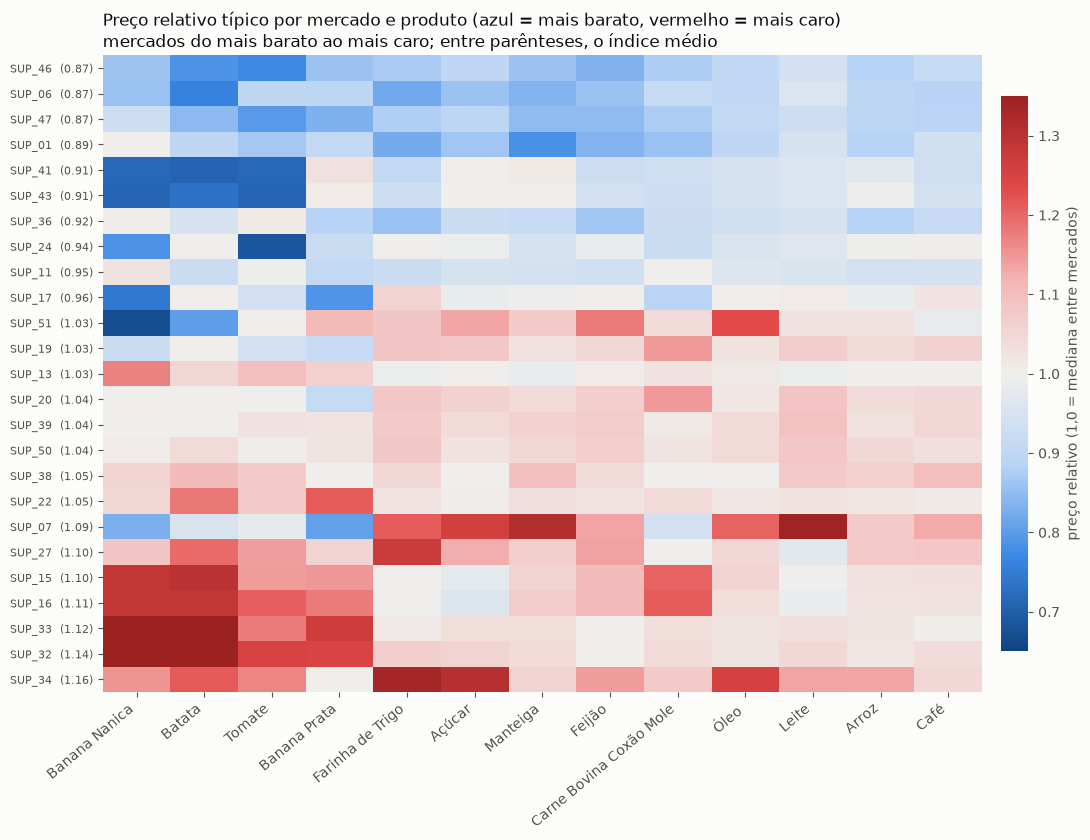

In [4]:
ordem = indice.sort_values().index
produtos_ordem = variacao.drop("Pão Francês").index  # do produto que mais varia ao que menos varia
dados = matriz.loc[ordem, produtos_ordem]

fig, eixo = plt.subplots(figsize=(11, 8.5))
limite = 0.35
imagem = eixo.imshow(dados.to_numpy(), cmap=DIVERGENTE, vmin=1 - limite, vmax=1 + limite, aspect="auto")
eixo.set_xticks(range(len(produtos_ordem)), produtos_ordem, rotation=40, ha="right")
eixo.set_yticks(range(len(ordem)), [f"{m}  ({indice[m]:.2f})" for m in ordem], fontsize=8)
eixo.grid(False)
for lado in eixo.spines.values():
    lado.set_visible(False)
barra = fig.colorbar(imagem, ax=eixo, fraction=0.03, pad=0.02)
barra.set_label("preço relativo (1,0 = mediana entre mercados)")
barra.outline.set_visible(False)
eixo.set_title("Preço relativo típico por mercado e produto (azul = mais barato, vermelho = mais caro)\n"
               "mercados do mais barato ao mais caro; entre parênteses, o índice médio", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "05_precos_relativos.png", dpi=150)
plt.show()

## 4. Escolha de k

Três critérios (aulas 11 e 12), calculados para k = 2 a 8:
- **cotovelo:** inércia (soma das distâncias ao quadrado até o centro do grupo); procura-se o ponto em que aumentar k deixa de reduzir muito a inércia;
- **silhueta:** de −1 a 1, maior é melhor;
- **Xie-Beni:** compactação ÷ separação entre os centros mais próximos, menor é melhor.

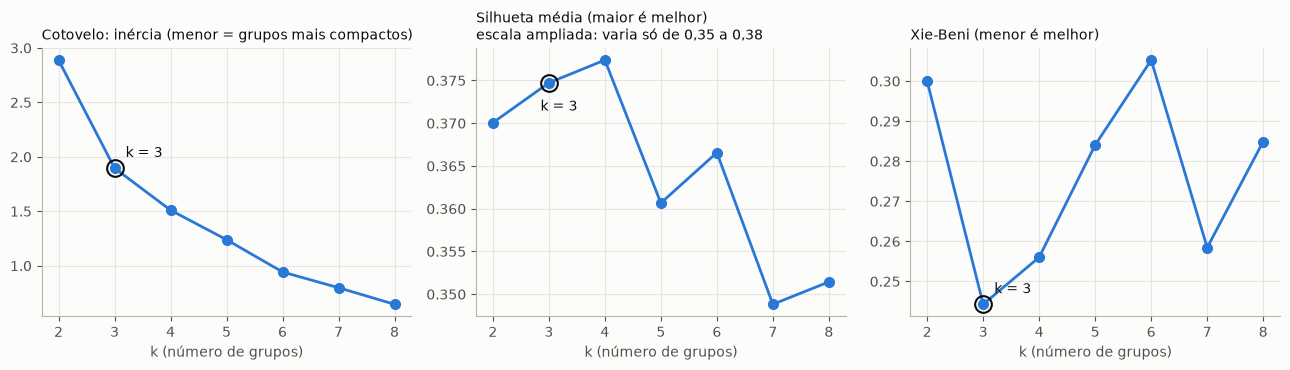

,k,inercia,silhueta,xie_beni,queda_inercia
0,2,2.8887,0.3701,0.3000,NaN
1,3,1.8965,0.3747,0.2443,0.9922
2,4,1.5104,0.3774,0.2560,0.3861
3,5,1.2390,0.3607,0.2841,0.2714
4,6,0.9426,0.3666,0.3053,0.2964
5,7,0.7980,0.3488,0.2584,0.1446
6,8,0.6458,0.3514,0.2849,0.1522


In [5]:
criterios = q3_clustering.avaliar_k(matriz)
criterios["queda_inercia"] = -criterios["inercia"].diff()
criterios.to_csv(config.DIR_TABELAS / "05_criterios_k.csv", index=False, encoding="utf-8")

k = config.K_ESCOLHIDO_Q3
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
paineis = [
    ("inercia", "Cotovelo: inércia (menor = grupos mais compactos)"),
    ("silhueta", "Silhueta média (maior é melhor)\nescala ampliada: varia só de 0,35 a 0,38"),
    ("xie_beni", "Xie-Beni (menor é melhor)"),
]
for eixo, (coluna, titulo) in zip(eixos, paineis):
    eixo.plot(criterios["k"], criterios[coluna], color=CORES_GRUPO[0], linewidth=2, marker="o", markersize=7)
    escolhido = criterios.loc[criterios["k"] == k, coluna].iloc[0]
    eixo.plot([k], [escolhido], marker="o", markersize=12, markerfacecolor="none", markeredgecolor=TEXTO, markeredgewidth=1.5)
    deslocamento = (-6, -20) if coluna == "silhueta" else (8, 8)
    eixo.annotate(f"k = {k}", (k, escolhido), textcoords="offset points", xytext=deslocamento, color=TEXTO)
    eixo.set_title(titulo, loc="left", fontsize=10)
    eixo.set_xlabel("k (número de grupos)")
    eixo.set_xticks(criterios["k"])
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "05_escolha_k.png", dpi=150)
plt.show()

criterios.round(4)

In [6]:
# A estabilidade no tempo também entra na escolha: um k cujos grupos mudam a cada ano não sustenta recomendação.
linhas = []
for kk in range(config.K_CLUSTERS_MIN, 6):
    tabela = q3_clustering.estabilidade_temporal(relativo, kk)
    linhas.append({
        "k": kk,
        "ari_vs_completo_medio": tabela["ari_vs_completo"].mean(),
        "ari_vs_completo_min": tabela["ari_vs_completo"].min(),
        "ari_vs_anterior_medio": tabela["ari_vs_anterior"].mean(),
        "ari_vs_anterior_min": tabela["ari_vs_anterior"].min(),
    })
estabilidade_por_k = pd.DataFrame(linhas)
estabilidade_por_k.to_csv(config.DIR_TABELAS / "05_estabilidade_por_k.csv", index=False, encoding="utf-8")
estabilidade_por_k.round(3)

,k,ari_vs_completo_medio,ari_vs_completo_min,ari_vs_anterior_medio,ari_vs_anterior_min
0,2,0.820,0.440,0.538,0.333
1,3,0.807,0.672,0.780,0.727
2,4,0.716,0.619,0.642,0.429
3,5,0.496,0.467,0.474,0.429


**Escolha: k = 3** (`config.K_ESCOLHIDO_Q3`).
- **Cotovelo:** a maior queda da inércia é de k = 2 para k = 3; de 3 para 4 a queda já é bem menor.
- **Xie-Beni:** mínimo em k = 3.
- **Silhueta:** praticamente empatada entre k = 2, 3 e 4 (diferença na terceira casa decimal), então não desempata. O valor em torno de 0,37 indica estrutura **moderada**: os mercados formam mais um gradiente de preço do que blocos bem separados (ver conclusão).
- **Estabilidade (tabela acima):** k = 3 tem o melhor pior caso (ARI mínimo de 0,67 contra o período completo, contra 0,44 de k = 2 e 0,62 de k = 4) e a maior concordância entre períodos consecutivos (ARI médio de 0,78). No ARI médio contra o período completo, k = 2 e k = 3 empatam (0,82 e 0,81).

## 5. Os grupos

Os grupos são numerados do mais barato (0) ao mais caro (`q3_clustering.ordenar_grupos`). O perfil de cada grupo é a média do preço relativo dos seus mercados em cada produto.

In [7]:
modelo = q3_clustering.ajustar_kmeans(matriz, k)
rotulos = q3_clustering.ordenar_grupos(matriz, modelo.labels_)
grupos = pd.DataFrame({"grupo": rotulos, "indice": indice}, index=matriz.index).sort_values(["grupo", "indice"])
grupos.rename_axis("mercado").to_csv(config.DIR_TABELAS / "05_grupos_mercados.csv", encoding="utf-8")

perfil = matriz.groupby(rotulos).mean()
perfil.index = [nome_grupo(g, k) for g in perfil.index]
perfil.T.round(3).to_csv(config.DIR_TABELAS / "05_perfil_grupos.csv", encoding="utf-8")

for g in range(k):
    membros = grupos[grupos["grupo"] == g]
    print(f"{nome_grupo(g, k)} ({len(membros)} mercados, índice médio {membros['indice'].mean():.3f}): {', '.join(membros.index)}")
perfil.T.round(3)

Grupo 0: mais baratos (10 mercados, índice médio 0.908): SUP_46, SUP_06, SUP_47, SUP_01, SUP_41, SUP_43, SUP_36, SUP_24, SUP_11, SUP_17
Grupo 1: intermediários (11 mercados, índice médio 1.059): SUP_51, SUP_19, SUP_13, SUP_20, SUP_39, SUP_50, SUP_38, SUP_22, SUP_07, SUP_27, SUP_34
Grupo 2: mais caros (4 mercados, índice médio 1.115): SUP_15, SUP_16, SUP_33, SUP_32


,Grupo 0: mais baratos,Grupo 1: intermediários,Grupo 2: mais caros
Café,0.939,1.049,1.025
Arroz,0.934,1.048,1.023
Feijão,0.903,1.083,1.053
Leite,0.958,1.081,1.016
Manteiga,0.914,1.072,1.050
Farinha de Trigo,0.907,1.117,1.020
Óleo,0.937,1.082,1.033
Açúcar,0.937,1.094,1.008
Tomate,0.839,1.046,1.196
Batata,0.861,1.049,1.378


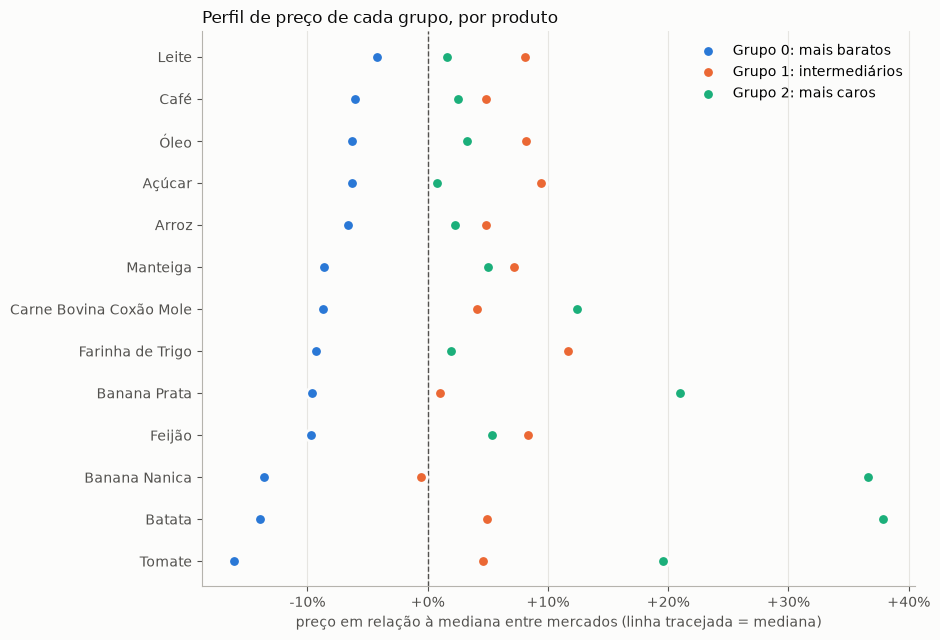

In [8]:
produtos_perfil = perfil.T.sort_values(perfil.index[0]).index  # do produto em que o grupo barato mais economiza
fig, eixo = plt.subplots(figsize=(9.5, 6.5))
eixo.axvline(1.0, color=TEXTO_2, linewidth=1, linestyle="--")
posicoes = np.arange(len(produtos_perfil))
for g, nome in enumerate(perfil.index):
    eixo.scatter(perfil.loc[nome, produtos_perfil], posicoes, s=70, color=CORES_GRUPO[g], label=nome,
                 edgecolor=SUPERFICIE, linewidth=2, zorder=3)
eixo.set_yticks(posicoes, produtos_perfil)
eixo.xaxis.set_major_formatter(lambda v, _: f"{(v - 1) * 100:+.0f}%")
eixo.set_xlabel("preço em relação à mediana entre mercados (linha tracejada = mediana)")
eixo.grid(axis="y", visible=False)
eixo.legend(loc="upper right", frameon=False)
eixo.set_title("Perfil de preço de cada grupo, por produto", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "05_perfil_grupos.png", dpi=150)
plt.show()

## 6. Quanto o consumidor economiza

A diferença de preço vira reais com a **Cesta Básica do DIEESE**, Região 1 (inclui SP): as quantidades mensais do Decreto-Lei 399/1938 que sustentam um trabalhador adulto por um mês (DIEESE, *Metodologia da Pesquisa Nacional da Cesta Básica de Alimentos*, ago/2025). Os 14 produtos do projeto são exatamente os 13 itens dessa cesta, com a banana em duas variedades.

Conversões (decisão 11):
- **Banana:** 90 unidades = 7,5 dúzias. O DIEESE converte o preço do kg em preço da dúzia multiplicando por 1,2 (prata) e 1,8 (nanica); como coletamos as duas, usamos metade das dúzias de cada (4,5 kg de prata e 6,75 kg de nanica).
- **Óleo:** 750 g ÷ 0,92 kg/L (densidade do óleo de soja) ≈ 0,82 L, porque o PPK do óleo está em R$/litro.
- **Pão Francês:** fica fora da conta, como no agrupamento. A tabela mostra o seu peso na cesta completa.

O preço de cada produto é a média do preço geral nos últimos 12 meses (set/2025–ago/2026), ou seja, valores de hoje. **Premissa:** o preço relativo típico de cada mercado (mediana do período todo) continua valendo hoje; a seção 7 testa isso.

In [9]:
precos = q3_clustering.preco_referencia_cesta(geral)
cesta = pd.DataFrame({
    "quantidade_mes": pd.Series(config.CESTA_DIEESE),
    "preco_geral_12m": precos,
})
cesta["custo_na_mediana"] = cesta["quantidade_mes"] * cesta["preco_geral_12m"]
cesta["na_q3"] = cesta.index.isin(config.PRODUTOS_Q3)
cesta = cesta.sort_values("custo_na_mediana", ascending=False)
cesta.rename_axis("produto").to_csv(config.DIR_TABELAS / "05_cesta_dieese.csv", encoding="utf-8")

total = cesta["custo_na_mediana"].sum()
sem_pao = cesta.loc[cesta["na_q3"], "custo_na_mediana"].sum()
print(f"Cesta DIEESE completa, na mediana: {reais(total)} | sem o pão (13 produtos da Q3): {reais(sem_pao)} "
      f"| o pão é {(1 - sem_pao / total) * 100:.1f}% da cesta")
cesta.round(2)

Cesta DIEESE completa, na mediana: R$ 845,59 | sem o pão (13 produtos da Q3): R$ 736,01 | o pão é 13.0% da cesta


,quantidade_mes,preco_geral_12m,custo_na_mediana,na_q3
Carne Bovina Coxão Mole,6.00,51.01,306.03,True
Pão Francês,6.00,18.26,109.58,False
Tomate,9.00,9.04,81.40,True
Manteiga,0.75,70.74,53.06,True
Banana Prata,4.50,11.19,50.37,True
Banana Nanica,6.75,7.09,47.86,True
Café,0.60,67.38,40.43,True
Leite,7.50,5.28,39.59,True
Feijão,4.50,8.41,37.83,True
Batata,6.00,5.80,34.82,True


In [10]:
economia = q3_clustering.economia_entre_grupos(matriz, rotulos, precos)
economia.insert(1, "nome", [nome_grupo(g, k) for g in economia["grupo"]])
economia.to_csv(config.DIR_TABELAS / "05_economia_grupos.csv", index=False, encoding="utf-8")

custo_mercado = q3_clustering.custo_cesta_por_mercado(matriz, precos).rename("custo_cesta").to_frame()
custo_mercado["grupo"] = grupos["grupo"]
custo_mercado.rename_axis("mercado").to_csv(config.DIR_TABELAS / "05_custo_cesta_mercados.csv", encoding="utf-8")

barato, caro = economia.iloc[0], economia.iloc[-1]
print(f"Cesta (13 produtos) no grupo mais barato: {reais(barato['custo_cesta'])} | no mais caro: {reais(caro['custo_cesta'])}")
print(f"Economia comprando no grupo mais barato em vez do mais caro: {reais(barato['economia_vs_mais_caro_rs_mes'])} por mês "
      f"({reais(barato['economia_vs_mais_caro_rs_ano'])} por ano)")
print(f"Em relação à mediana: {reais(-barato['dif_mediana_rs'])} por mês ({-barato['dif_mediana_pct']:.1f}%)")
print(f"Mercado mais barato x mais caro: {reais(custo_mercado['custo_cesta'].iloc[0])} ({custo_mercado.index[0]}) x "
      f"{reais(custo_mercado['custo_cesta'].iloc[-1])} ({custo_mercado.index[-1]})")
economia.drop(columns="mercados").round(2)

Cesta (13 produtos) no grupo mais barato: R$ 664,53 | no mais caro: R$ 838,30
Economia comprando no grupo mais barato em vez do mais caro: R$ 173,77 por mês (R$ 2.085,24 por ano)
Em relação à mediana: R$ 71,48 por mês (9.7%)
Mercado mais barato x mais caro: R$ 633,91 (SUP_46) x R$ 859,01 (SUP_16)


,grupo,nome,n_mercados,indice_medio,custo_cesta,dif_mediana_rs,dif_mediana_pct,economia_vs_mais_caro_rs_mes,economia_vs_mais_caro_rs_ano
0,0,Grupo 0: mais baratos,10,0.91,664.53,-71.48,-9.71,173.77,2085.24
1,1,Grupo 1: intermediários,11,1.06,769.97,33.96,4.61,68.33,819.99
2,2,Grupo 2: mais caros,4,1.12,838.30,102.29,13.90,0.00,0.00


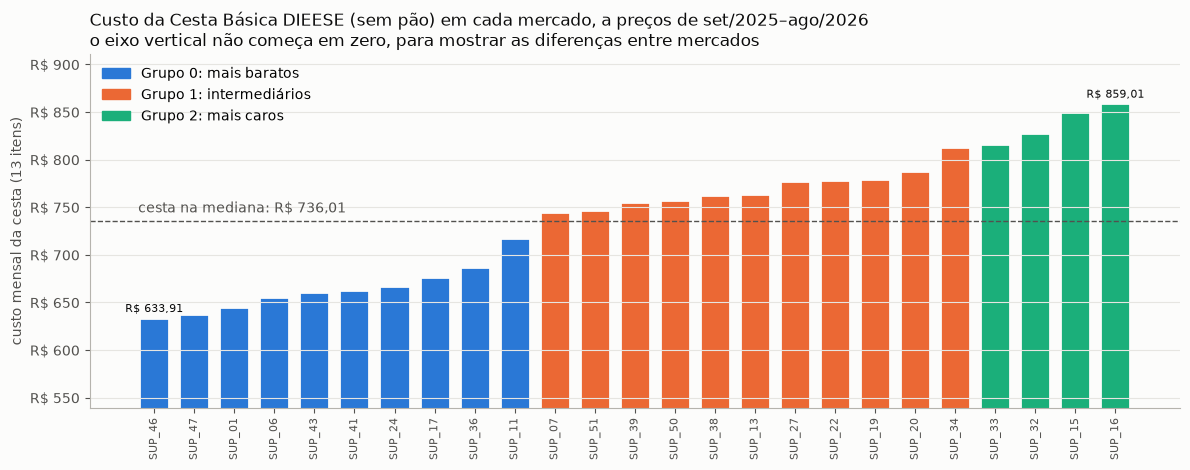

In [11]:
fig, eixo = plt.subplots(figsize=(12, 4.8))
posicoes = np.arange(len(custo_mercado))
eixo.bar(posicoes, custo_mercado["custo_cesta"], width=0.75,
         color=[CORES_GRUPO[g] for g in custo_mercado["grupo"]], edgecolor=SUPERFICIE, linewidth=2)
mediana_cesta = q3_clustering.custo_cesta(pd.Series(1.0, index=matriz.columns), precos)
eixo.axhline(mediana_cesta, color=TEXTO_2, linewidth=1, linestyle="--")
eixo.text(-0.4, mediana_cesta + 5, f"cesta na mediana: {reais(mediana_cesta)}", ha="left", va="bottom", color=TEXTO_2)
for i in (0, len(posicoes) - 1):
    eixo.text(i, custo_mercado["custo_cesta"].iloc[i] + 6, reais(custo_mercado["custo_cesta"].iloc[i]),
              ha="center", fontsize=8, color=TEXTO)
eixo.set_ylim(custo_mercado["custo_cesta"].min() * 0.85, custo_mercado["custo_cesta"].max() * 1.06)
eixo.set_xticks(posicoes, custo_mercado.index, rotation=90, fontsize=8)
eixo.yaxis.set_major_formatter(lambda v, _: f"R$ {v:.0f}")
eixo.set_ylabel("custo mensal da cesta (13 itens)")
eixo.grid(axis="x", visible=False)
eixo.legend(handles=[Patch(color=CORES_GRUPO[g], label=nome_grupo(g, k)) for g in range(k)], loc="upper left", frameon=False)
eixo.set_title("Custo da Cesta Básica DIEESE (sem pão) em cada mercado, a preços de set/2025–ago/2026\n"
               "o eixo vertical não começa em zero, para mostrar as diferenças entre mercados", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "05_custo_cesta_mercados.png", dpi=150)
plt.show()

## 7. Estabilidade no tempo

O agrupamento é refeito separadamente em 4 períodos de 12 meses (set a ago; `config.PERIODOS_ESTABILIDADE`) e comparado com o do período completo:
- **ARI** (adjusted Rand index): 1 = mesmos grupos, ~0 = concordância de acaso; não depende da numeração dos grupos;
- **% no mesmo grupo:** com os grupos ordenados do mais barato ao mais caro;
- **Spearman do índice:** correlação de postos da ordem dos mercados (do mais barato ao mais caro), que não depende do K-Means.

Atenção: os meses faltantes dos 25 mercados se concentram a partir de ago/2025 (decisão 4), então o último período se apoia em menos meses por mercado.

In [12]:
grupos_periodo = q3_clustering.grupos_por_periodo(relativo, k)
estabilidade = q3_clustering.estabilidade_temporal(relativo, k)
grupos_periodo.rename_axis("mercado").to_csv(config.DIR_TABELAS / "05_grupos_por_periodo.csv", encoding="utf-8")
estabilidade.to_csv(config.DIR_TABELAS / "05_estabilidade.csv", index=False, encoding="utf-8")

mudam = grupos_periodo[grupos_periodo.nunique(axis=1) > 1]
print(f"{len(grupos_periodo) - len(mudam)} de {len(grupos_periodo)} mercados ficam no mesmo grupo nos 4 períodos e no completo.")
print("Os que mudam:")
display(mudam)
estabilidade.round(3)

21 de 25 mercados ficam no mesmo grupo nos 4 períodos e no completo.
Os que mudam:


,completo,2022-09 a 2023-08,2023-09 a 2024-08,2024-09 a 2025-08,2025-09 a 2026-08
mercado,,,,,
SUP_13,1,2,2,1,1
SUP_17,0,1,0,0,1
SUP_22,1,2,2,1,1
SUP_34,1,1,1,2,1


,periodo,ari_vs_completo,ari_vs_anterior,pct_mesmo_grupo,spearman_indice
0,2022-09 a 2023-08,0.672,NaN,88.0,0.956
1,2023-09 a 2024-08,0.806,0.862,92.0,0.977
2,2024-09 a 2025-08,0.897,0.727,96.0,0.987
3,2025-09 a 2026-08,0.855,0.750,96.0,0.968


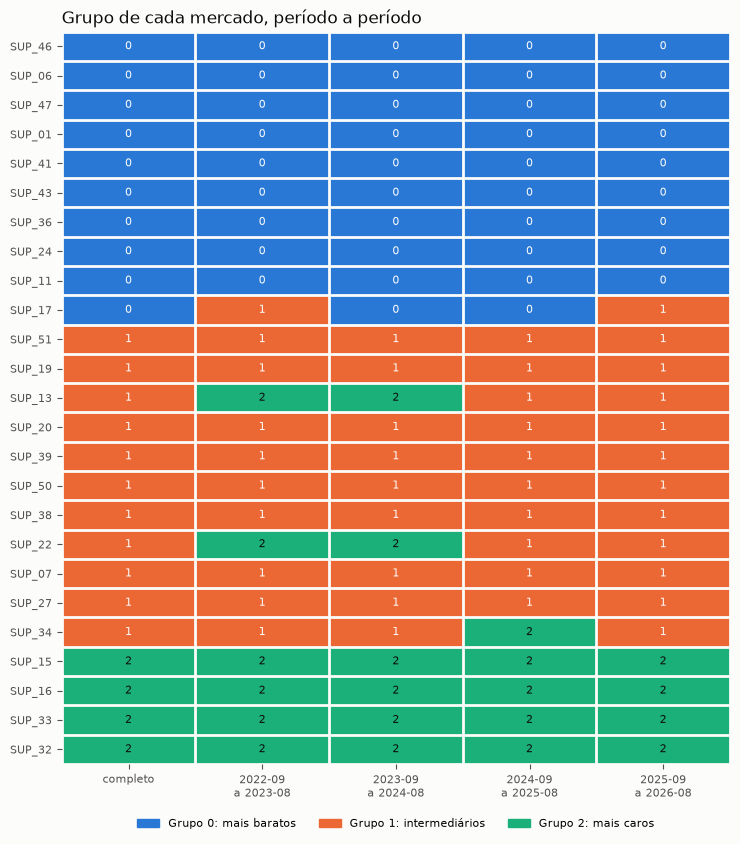

In [13]:
ordem_mercados = grupos.index  # mesma ordem da seção 5 (grupo, depois índice)
dados = grupos_periodo.loc[ordem_mercados]
fig, eixo = plt.subplots(figsize=(7.5, 8.5))
eixo.imshow(dados.to_numpy(), cmap=ListedColormap(CORES_GRUPO[:k]), vmin=-0.5, vmax=k - 0.5, aspect="auto")
eixo.set_xticks(range(dados.shape[1]), [c.replace(" a ", "\na ") for c in dados.columns], fontsize=8)
eixo.set_yticks(range(len(dados)), dados.index, fontsize=8)
eixo.set_xticks(np.arange(-0.5, dados.shape[1]), minor=True)
eixo.set_yticks(np.arange(-0.5, len(dados)), minor=True)
eixo.grid(which="minor", color=SUPERFICIE, linewidth=2)
eixo.grid(which="major", visible=False)
eixo.tick_params(which="minor", length=0)
for lado in eixo.spines.values():
    lado.set_visible(False)
for (i, j), g in np.ndenumerate(dados.to_numpy()):
    eixo.text(j, i, g, ha="center", va="center", fontsize=8, color=TEXTO if g == 2 else SUPERFICIE)
eixo.legend(handles=[Patch(color=CORES_GRUPO[g], label=nome_grupo(g, k)) for g in range(k)],
            loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=k, frameon=False, fontsize=8)
eixo.set_title("Grupo de cada mercado, período a período", loc="left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "05_grupos_por_periodo.png", dpi=150)
plt.show()

## 8. Conclusão

**Existem mercados consistentemente mais baratos? Sim.**
- O K-Means com k = 3 separa **10 dos 25 mercados** num grupo barato, com preço em média **9% abaixo da mediana** (índice 0,91). Esse grupo é mais barato em **todos os 13 produtos** (todos os pontos azuis ficam à esquerda da mediana na seção 5), e não só em alguns itens em promoção.
- **É consistente no tempo:** refazendo o agrupamento em cada período de 12 meses, 9 desses 10 mercados ficam no grupo barato nos 4 períodos. Só o SUP_17, o mais caro do grupo (índice 0,96, na fronteira), oscila. A ordem dos mercados do mais barato ao mais caro quase não muda: Spearman de 0,96 a 0,99 entre cada período e o período completo. Esse resultado não depende do K-Means.

**Quanto o consumidor economiza?** Com a Cesta Básica do DIEESE (sem pão), a preços de set/2025–ago/2026:
- no grupo barato, a cesta custa **R$ 664,53**, contra **R$ 736,01** na mediana (**R$ 71,48 a menos por mês, 9,7%**) e **R$ 838,30** no grupo mais caro (**R$ 173,77 por mês, cerca de R$ 2.085 por ano**);
- entre o mercado mais barato (SUP_46, R$ 633,91) e o mais caro (SUP_16, R$ 859,01), a diferença é de **R$ 225,10 por mês**.

**Os grupos diferem também no tipo de produto, não só no nível de preço:**
- o grupo 2 (4 mercados) é caro sobretudo no **hortifrúti** (batata +38%, banana nanica +37%, banana prata +21%, tomate +20%) e fica perto da mediana nos industrializados;
- o grupo 1 (11 mercados) é o contrário: mais caro nos **industrializados** (farinha +12%, açúcar +9%, leite, óleo e feijão +8%) e perto da mediana no hortifrúti.
- Recomendação prática: quem compra num mercado do grupo 2 economiza comprando o hortifrúti em outro lugar.

**Ressalvas:**
- **Estrutura moderada:** a silhueta em torno de 0,37 e o mapa de calor da seção 3 mostram que os mercados formam mais um **gradiente** de preço do que blocos bem separados. Os grupos são um resumo útil desse gradiente, e a conclusão principal (há mercados consistentemente baratos) vale também sem eles, pela estabilidade da ordem.
- **Marca e qualidade:** o preço de um mercado é a mediana das marcas que ele vende. Um mercado pode ser "barato" em parte por vender marcas mais baratas, e não só por cobrar menos pelo mesmo item.
- **Custos fora da conta:** os mercados baratos parecem incluir atacarejos (vários não vendem pão). Deslocamento, compra em volume e tempo não entram na economia calculada.
- **Premissas da conversão em R$:** o preço relativo típico de cada mercado vale para os preços de hoje (apoiado pela estabilidade da seção 7); a banana é metade prata e metade nanica; o coxão mole representa a carne; e o pão fica fora (13% da cesta completa).
- **Anonimização:** o trabalho mostra que esses mercados existem e quanto valem, mas não quais são.